# 7CS353 Machine Learning Lab — Assignment 7
### Classification: Logistic Regression and Perceptron Learning

Name: Atharv V Kulkarni
PRN: 245109074
Class: TY CSE(B)

## B1. Load and explore

In [51]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, Perceptron
from sklearn.metrics import confusion_matrix, classification_report, roc_curve, auc, accuracy_score, precision_score, recall_score, f1_score
np.random.seed(42)

In [52]:
import os
if os.path.exists("student_pass.csv"):
    df = pd.read_csv("student_pass.csv")
else:
    rng = np.random.default_rng(seed=42)
    n = 500
    study = rng.normal(5, 1.8, n).clip(0.5, 10).round(2)
    attendance = rng.normal(72, 15, n).clip(30, 100).round(1)
    z = -5 + 0.6*study + 0.04*attendance
    prob = 1 / (1 + np.exp(-z))
    y = rng.binomial(1, prob, n)
    df = pd.DataFrame({"study_hours": study, "attendance": attendance, "pass": y})
    df.to_csv("student_pass.csv", index=False)
print(df.shape)
print(df["pass"].value_counts())

(500, 3)
pass
1    326
0    174
Name: count, dtype: int64


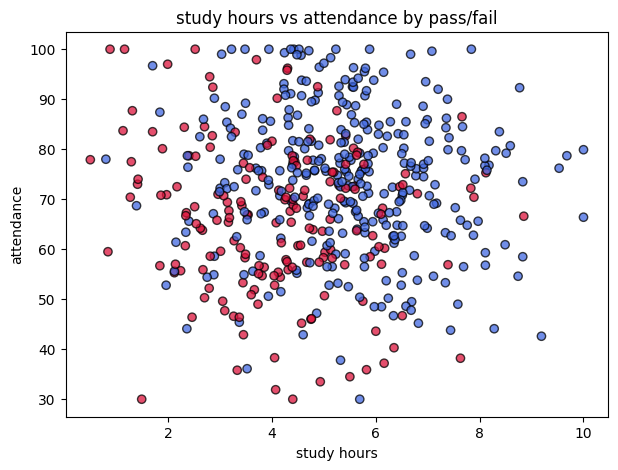

In [53]:
fig, ax = plt.subplots(figsize=(7,5))
colors = df["pass"].map({0: "crimson", 1: "royalblue"})
ax.scatter(df["study_hours"], df["attendance"], c=colors, edgecolor="k", alpha=0.75)
ax.set_xlabel("study hours")
ax.set_ylabel("attendance")
ax.set_title("study hours vs attendance by pass/fail")
plt.show()

## B2. Preprocessing

In [54]:
x = df[["study_hours", "attendance"]].values
y = df["pass"].values
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y)

In [55]:
scaler = StandardScaler()
x_train_s = scaler.fit_transform(x_train)
x_test_s = scaler.transform(x_test)
print(x_train_s.mean(axis=0), x_train_s.std(axis=0))

[-1.78190795e-16  6.23112673e-16] [1. 1.]


## B3. Logistic regression from scratch

In [56]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))
#binary cross entropy loss
def bce_loss(y_true, y_pred):
    eps = 1e-12
    y_pred = np.clip(y_pred, eps, 1 - eps)
    return -np.mean(y_true*np.log(y_pred) + (1-y_true)*np.log(1-y_pred))

In [57]:
def train_logistic(x, y, lr=0.1, epochs=2000):
    n, d = x.shape
    w = np.zeros(d)
    b = 0.0
    losses = []
    for epoch in range(epochs):
        z = x @ w + b
        y_hat = sigmoid(z)
        loss = bce_loss(y, y_hat)
        losses.append(loss)
        dw = (1/n) * x.T @ (y_hat - y)
        db = (1/n) * np.sum(y_hat - y)
        w -= lr * dw
        b -= lr * db
    return w, b, losses

w_log, b_log, loss_history = train_logistic(x_train_s, y_train)

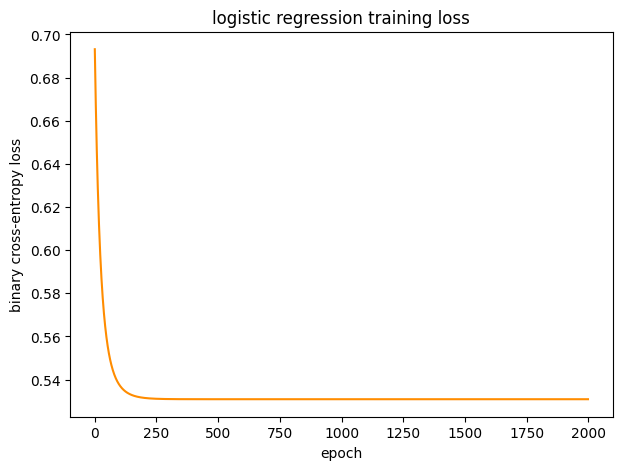

In [58]:
fig, ax = plt.subplots(figsize=(7,5))
ax.plot(loss_history, color="darkorange")
ax.set_xlabel("epoch")
ax.set_ylabel("binary cross-entropy loss")
ax.set_title("logistic regression training loss")
plt.show()

In [59]:
print("scratch w:", w_log, "scratch b:", b_log)
sk_log = LogisticRegression()
sk_log.fit(x_train_s, y_train)
print("sklearn w:", sk_log.coef_[0], "sklearn b:", sk_log.intercept_[0])

scratch w: [1.02437921 0.60371449] scratch b: 0.8028142182608543
sklearn w: [1.00359294 0.59175718] sklearn b: 0.7969237312848904


## B4. Perceptron from scratch

In [60]:
def step(z):
    return np.where(z >= 0, 1, 0)

def train_perceptron(x, y, lr=0.1, epochs=2000):
    n, d = x.shape
    w = np.zeros(d)
    b = 0.0
    mistakes_per_epoch = []

    for epoch in range(epochs):
        mistakes = 0

        for i in range(n):
            z = np.dot(w, x[i]) + b
            y_hat = step(z)

            if y_hat != y[i]:
                w = w + lr * (y[i] - y_hat) * x[i]
                b = b + lr * (y[i] - y_hat)
                mistakes += 1

        mistakes_per_epoch.append(mistakes)

        # Print results for every epoch
        print(f"Epoch {epoch + 1}: Mistakes = {mistakes}, "
              f"Weights = {w}, Bias = {b:.4f}")

    return w, b, mistakes_per_epoch


w_perc, b_perc, mistake_history = train_perceptron(
    x_train_s, y_train, lr=0.1, epochs=500
)

print("\nFinal weights:", w_perc)
print("Final bias:", b_perc)
print("Total epochs:", len(mistake_history))
print("Mistakes in last epoch:", mistake_history[-1])

Epoch 1: Mistakes = 146, Weights = [0.14400441 0.06865688], Bias = 0.0000
Epoch 2: Mistakes = 151, Weights = [0.20292001 0.16014548], Bias = 0.1000
Epoch 3: Mistakes = 144, Weights = [0.13694189 0.06310162], Bias = 0.1000
Epoch 4: Mistakes = 140, Weights = [0.11915648 0.09280892], Bias = 0.1000
Epoch 5: Mistakes = 152, Weights = [0.22586892 0.13043817], Bias = 0.1000
Epoch 6: Mistakes = 150, Weights = [0.14899007 0.05848048], Bias = 0.1000
Epoch 7: Mistakes = 142, Weights = [0.35438282 0.01623009], Bias = 0.1000
Epoch 8: Mistakes = 146, Weights = [ 0.31823828 -0.02668046], Bias = 0.1000
Epoch 9: Mistakes = 150, Weights = [0.20292001 0.15882515], Bias = 0.1000
Epoch 10: Mistakes = 144, Weights = [0.13694189 0.06178129], Bias = 0.1000
Epoch 11: Mistakes = 140, Weights = [0.11915648 0.0914886 ], Bias = 0.1000
Epoch 12: Mistakes = 152, Weights = [0.22586892 0.12911785], Bias = 0.1000
Epoch 13: Mistakes = 152, Weights = [0.22529519 0.13637963], Bias = 0.1000
Epoch 14: Mistakes = 140, Weight

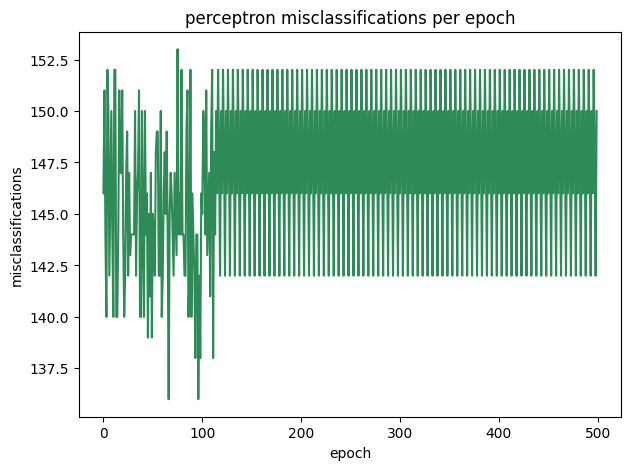

In [61]:
fig, ax = plt.subplots(figsize=(7,5))
ax.plot(mistake_history, color="seagreen")
ax.set_xlabel("epoch")
ax.set_ylabel("misclassifications")
ax.set_title("perceptron misclassifications per epoch")
plt.show()

In [62]:
print("scratch w:", w_perc, "scratch b:", b_perc)
sk_perc = Perceptron()
sk_perc.fit(x_train_s, y_train)
print("sklearn w:", sk_perc.coef_[0], "sklearn b:", sk_perc.intercept_[0])

scratch w: [0.17136525 0.17929019] scratch b: 0.10000000000000003
sklearn w: [ 1.84560877 -0.42524356] sklearn b: 1.0


## B5. Evaluation

In [63]:
z_log_test = x_test_s @ w_log + b_log
y_prob_log = sigmoid(z_log_test)
y_pred_log = (y_prob_log >= 0.5).astype(int)

z_perc_test = x_test_s @ w_perc + b_perc
y_pred_perc = step(z_perc_test)

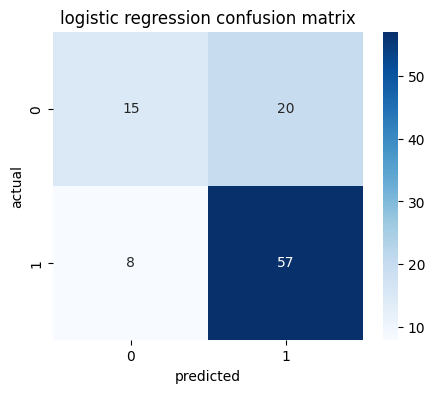

In [64]:
cm_log = confusion_matrix(y_test, y_pred_log)
fig, ax = plt.subplots(figsize=(5,4))
sns.heatmap(cm_log, annot=True, fmt="d", cmap="Blues", ax=ax)
ax.set_xlabel("predicted")
ax.set_ylabel("actual")
ax.set_title("logistic regression confusion matrix")
plt.show()

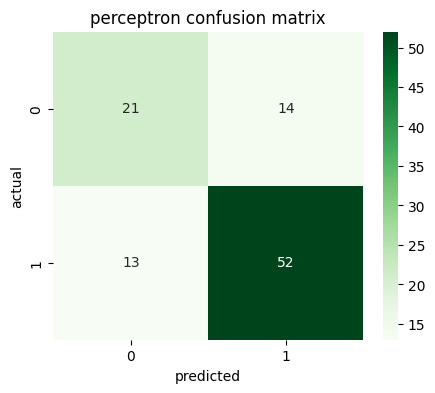

In [65]:
cm_perc = confusion_matrix(y_test, y_pred_perc)
fig, ax = plt.subplots(figsize=(5,4))
sns.heatmap(cm_perc, annot=True, fmt="d", cmap="Greens", ax=ax)
ax.set_xlabel("predicted")
ax.set_ylabel("actual")
ax.set_title("perceptron confusion matrix")
plt.show()

In [66]:
print("logistic regression report")
print(classification_report(y_test, y_pred_log))
print("perceptron report")
print(classification_report(y_test, y_pred_perc))

logistic regression report
              precision    recall  f1-score   support

           0       0.65      0.43      0.52        35
           1       0.74      0.88      0.80        65

    accuracy                           0.72       100
   macro avg       0.70      0.65      0.66       100
weighted avg       0.71      0.72      0.70       100

perceptron report
              precision    recall  f1-score   support

           0       0.62      0.60      0.61        35
           1       0.79      0.80      0.79        65

    accuracy                           0.73       100
   macro avg       0.70      0.70      0.70       100
weighted avg       0.73      0.73      0.73       100



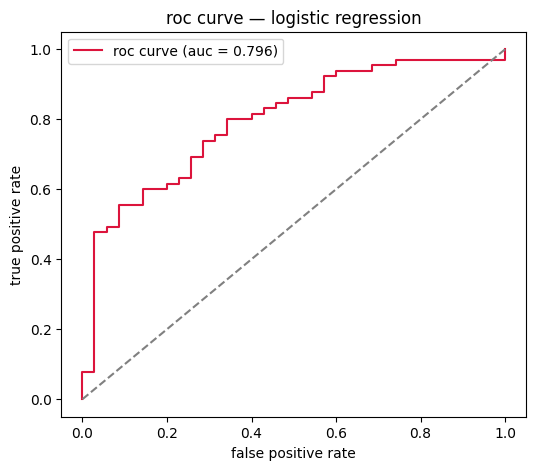

In [67]:
fpr, tpr, thresholds = roc_curve(y_test, y_prob_log)
roc_auc = auc(fpr, tpr)
fig, ax = plt.subplots(figsize=(6,5))
ax.plot(fpr, tpr, color="crimson", label="roc curve (auc = %.3f)" % roc_auc)
ax.plot([0,1],[0,1], linestyle="--", color="gray")
ax.set_xlabel("false positive rate")
ax.set_ylabel("true positive rate")
ax.set_title("roc curve — logistic regression")
ax.legend()
plt.show()

In [68]:
acc_log = accuracy_score(y_test, y_pred_log)
prec_log = precision_score(y_test, y_pred_log)
rec_log = recall_score(y_test, y_pred_log)
f1_log = f1_score(y_test, y_pred_log)

acc_perc = accuracy_score(y_test, y_pred_perc)
prec_perc = precision_score(y_test, y_pred_perc)
rec_perc = recall_score(y_test, y_pred_perc)
f1_perc = f1_score(y_test, y_pred_perc)

print("logistic regression", acc_log, prec_log, rec_log, f1_log, roc_auc)
print("perceptron", acc_perc, prec_perc, rec_perc, f1_perc)

logistic regression 0.72 0.7402597402597403 0.8769230769230769 0.8028169014084507 0.7956043956043957
perceptron 0.73 0.7878787878787878 0.8 0.7938931297709924


## B6. Decision boundaries

In [69]:
def plot_boundary(ax, w, b, scaler, predict_fn, title):
    x_min, x_max = df["study_hours"].min()-0.5, df["study_hours"].max()+0.5
    y_min, y_max = df["attendance"].min()-2, df["attendance"].max()+2
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))
    grid = np.c_[xx.ravel(), yy.ravel()]
    grid_s = scaler.transform(grid)
    zz = predict_fn(grid_s, w, b).reshape(xx.shape)
    ax.contourf(xx, yy, zz, levels=[-0.5,0.5,1.5], colors=["mistyrose","lightsteelblue"], alpha=0.6)
    colors = df["pass"].map({0: "crimson", 1: "royalblue"})
    ax.scatter(df["study_hours"], df["attendance"], c=colors, edgecolor="k", alpha=0.8)
    ax.set_xlabel("study hours")
    ax.set_ylabel("attendance")
    ax.set_title(title)

def predict_log(x_s, w, b):
    return (sigmoid(x_s @ w + b) >= 0.5).astype(int)

def predict_perc(x_s, w, b):
    return step(x_s @ w + b)

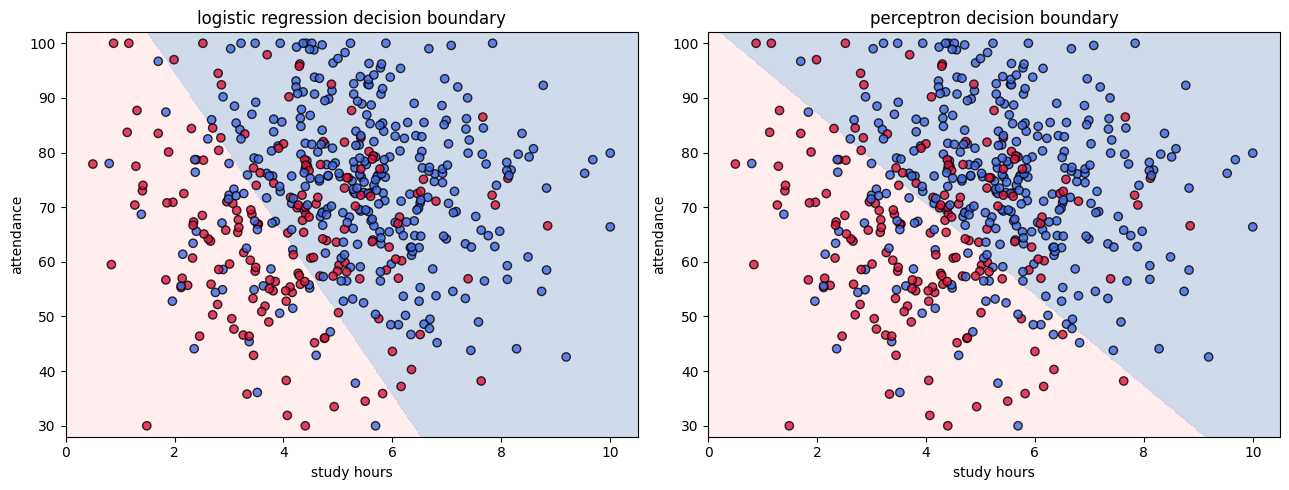

In [70]:
fig, axes = plt.subplots(1, 2, figsize=(13,5))
plot_boundary(axes[0], w_log, b_log, scaler, predict_log, "logistic regression decision boundary")
plot_boundary(axes[1], w_perc, b_perc, scaler, predict_perc, "perceptron decision boundary")
plt.tight_layout()
plt.show()